# Problem 4: Evaluating an Object Detector

The detections below come from the pretrained FCOS (ResNet-50 FPN) detector in torchvision, run on three images with a score threshold of 0.05 and **without** non-maximum suppression. They are saved in `data/detections.npz`, so you do not need PyTorch. The optional last section shows how they were produced.

All of your code goes in `P4_detection.py`.

In [24]:
%load_ext autoreload
%autoreload 2

import os
import numpy as np
import matplotlib.pyplot as plt

import matplotlib.patches as patches
from P4_detection import box_iou, nms, batched_nms, match_detections, precision_recall, average_precision

os.makedirs("plots", exist_ok=True)

det = np.load("data/detections.npz")
categories = list(det["categories"])
IMAGES = {"cars": "data/cars.jpg", "airport": "data/airport.jpeg", "dog_park": "data/dog_park.jpeg"}

def show_detections(name, boxes, scores, labels, title, filename=None):
    fig, ax = plt.subplots(figsize=(8, 5))
    ax.imshow(plt.imread(IMAGES[name]))
    for (x1, y1, x2, y2), s, l in zip(boxes, scores, labels):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="r"))
        ax.text(x1, y1, f"{categories[l]} [p = {s:.2f}]", color="w", fontsize=7, bbox=dict(facecolor="r", alpha=0.6, pad=0))
    ax.set_title(title)
    ax.axis("off")
    if filename is not None:
        plt.savefig(filename, bbox_inches="tight")
    plt.show()

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## Sanity Checks

In [25]:
a = np.array([[0., 0, 2, 2], [1, 1, 3, 3]])
b = np.array([[0., 0, 2, 2], [10, 10, 11, 11]])
assert np.allclose(box_iou(a, b), [[1, 0], [1 / 7, 0]])
boxes = np.array([[0., 0, 10, 10], [1, 1, 11, 11], [20, 20, 30, 30]])
scores = np.array([0.9, 0.8, 0.7])
assert np.array_equal(nms(boxes, scores, 0.5), [0, 2])
assert np.array_equal(batched_nms(boxes, scores, np.array([1, 2, 1]), 0.5), [0, 1, 2])
tp = match_detections(boxes, scores, np.array([[0., 0, 10, 10]]))
assert np.array_equal(tp, [True, False, False])
p, r = precision_recall(scores, tp, 1)
assert np.allclose(p, [1, 0.5, 1 / 3]) and np.allclose(r, [1, 1, 1])
assert np.isclose(average_precision(p, r), 1.0)
print("Sanity checks passed")

[1.         0.5        0.33333333]
Sanity checks passed


## Non-Maximum Suppression

cars: 5000 raw detections, 1145 after NMS, same as the model's own NMS: True
airport: 4862 raw detections, 1633 after NMS, same as the model's own NMS: True
dog_park: 4926 raw detections, 1299 after NMS, same as the model's own NMS: True


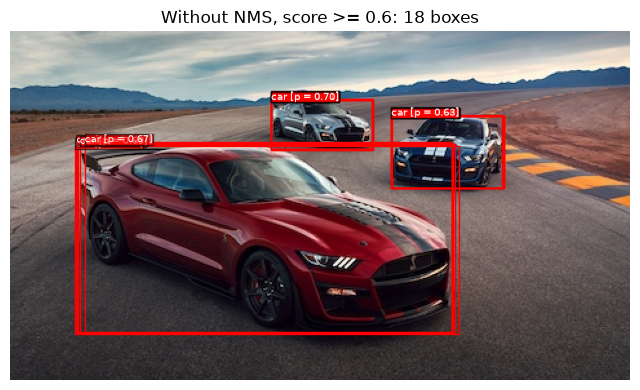

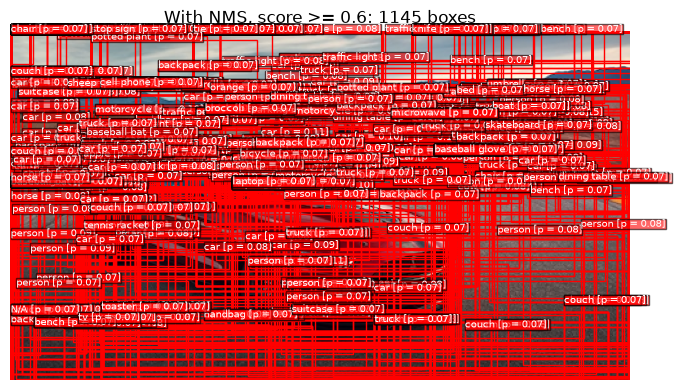

In [ ]:
for name in IMAGES:
    boxes, scores, labels = det[name + "_boxes"].astype(float), det[name + "_scores"].astype(float), det[name + "_labels"]
    keep = batched_nms(boxes, scores, labels, 0.6)
    print(f"{name}: {len(boxes)} raw detections, {len(keep)} after NMS, same as the model's own NMS: {np.array_equal(keep, det[name + '_model_keep'])}")

name = "cars"
boxes, scores, labels = det[name + "_boxes"].astype(float), det[name + "_scores"].astype(float), det[name + "_labels"]
m = scores >= 0.6
show_detections(name, boxes[m], scores[m], labels[m], f"Without NMS, score >= 0.6: {m.sum()} boxes")
keep = batched_nms(boxes, scores, labels, 0.6)
show_detections(name, boxes[keep], scores[keep], labels[keep], f"With NMS, score >= 0.6: {len(keep)} boxes", "plots/p4_cars.png")

## Precision, Recall, and Average Precision
The airplanes in the airport image have been labeled by hand in `data/airport_gt.npz`. Use this section for part (ii).

AP with NMS: 0.866, without NMS: 0.831
 threshold | detections | TP | precision | recall
   0.70    |       3    |  3 |   1.000   | 0.429
   0.50    |       5    |  4 |   0.800   | 0.571
   0.30    |      19    |  6 |   0.316   | 0.857
   0.10    |     324    |  7 |   0.022   | 1.000


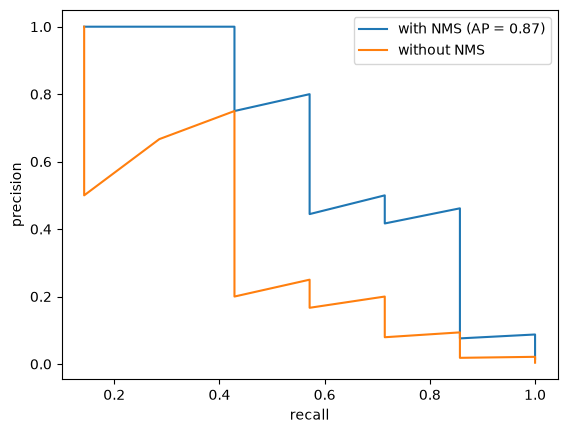

In [ ]:
gt = np.load("data/airport_gt.npz")["boxes"].astype(float)
name = "airport"
boxes, scores, labels = det[name + "_boxes"].astype(float), det[name + "_scores"].astype(float), det[name + "_labels"]
plane = labels == categories.index("airplane")

keep = batched_nms(boxes, scores, labels, 0.6)
keep = keep[plane[keep]]
tp = match_detections(boxes[keep], scores[keep], gt)
precision, recall = precision_recall(scores[keep], tp, len(gt))
ap = average_precision(precision, recall)

raw = np.where(plane)[0]
tp_raw = match_detections(boxes[raw], scores[raw], gt)
p_raw, r_raw = precision_recall(scores[raw], tp_raw, len(gt))
print(f"AP with NMS: {ap:.3f}, without NMS: {average_precision(p_raw, r_raw):.3f}")

print(" threshold | detections | TP | precision | recall")
for th in [0.7, 0.5, 0.3, 0.1]:
    m = scores[keep] >= th
    n_tp = match_detections(boxes[keep][m], scores[keep][m], gt).sum()
    print(f"   {th:4.2f}    |   {m.sum():5d}    | {n_tp:2d} |   {n_tp / max(m.sum(), 1):.3f}   | {n_tp / len(gt):.3f}")

plt.figure()
plt.plot(recall, precision, label=f"with NMS (AP = {ap:.2f})")
plt.plot(r_raw, p_raw, label="without NMS")
plt.xlabel("recall")
plt.ylabel("precision")
plt.legend()
plt.savefig("plots/p4_pr.png", bbox_inches="tight")
plt.show()

## Running the Detector Yourself
Use this section for part (iv). It needs `torch` and `torchvision` (`pip install torch torchvision`; the CPU version is fine) and downloads about 130 MB of weights the first time. If you would rather not install them, run this notebook in Google Colab and upload `P4_detection.py` and your photo next to it.

Take a photo with several objects from the COCO classes (people, cars, bicycles, chairs, cups, bottles, laptops, ...), save it next to this notebook, and set `MY_IMAGE` to its file name. The model below is built with `nms_thresh=1.0`, so it returns raw detections and your `batched_nms` does the suppression.

In [ ]:
import torch
from torchvision.io import read_image
from torchvision.transforms.functional import resize
from torchvision.models.detection import fcos_resnet50_fpn, FCOS_ResNet50_FPN_Weights

MY_IMAGE = "data/airport.jpeg"

weights = FCOS_ResNet50_FPN_Weights.DEFAULT
image = read_image(MY_IMAGE)[:3]          # uint8 tensor, shape (3, H, W), values 0 to 255
if max(image.shape[1:]) > 800:
    image = resize(image, 800 * min(image.shape[1:]) // max(image.shape[1:]))

############################## Code starts here ##############################
# Build the model with fcos_resnet50_fpn(weights=weights, score_thresh=0.05, nms_thresh=1.0, detections_per_img=10000),
# put it in evaluation mode, and run it on the image. The model expects a list of float images with values in [0, 1].
# Store the outputs for the image as numpy arrays my_boxes (K, 4), my_scores (K,), my_labels (K,).
raise NotImplementedError
############################## Code ends here ##############################

print(len(my_scores), "raw detections")
keep = batched_nms(my_boxes, my_scores, my_labels, 0.6)
keep = keep[my_scores[keep] >= 0.5]
raw = np.where(my_scores >= 0.5)[0]

fig, axs = plt.subplots(1, 2, figsize=(14, 5))
for ax, idx, title in [(axs[0], raw, f"Raw, score >= 0.5: {len(raw)} boxes"), (axs[1], keep, f"After NMS, score >= 0.5: {len(keep)} boxes")]:
    ax.imshow(image.permute(1, 2, 0).numpy())
    for (x1, y1, x2, y2), s, l in zip(my_boxes[idx], my_scores[idx], my_labels[idx]):
        ax.add_patch(patches.Rectangle((x1, y1), x2 - x1, y2 - y1, fill=False, color="r"))
        ax.text(x1, y1, f"{categories[l]} [p = {s:.2f}]", color="w", fontsize=7, bbox=dict(facecolor="r", alpha=0.6, pad=0))
    ax.set_title(title)
    ax.axis("off")
plt.savefig("plots/p4_own_image.png", bbox_inches="tight")
plt.show()

NotImplementedError: 